In [1]:
# import torch
# import sys

# try:
#     print(f"PyTorch version: {torch.__version__}")
#     print(f"CUDA available: {torch.cuda.is_available()}")
#     print(f"CUDA device count: {torch.cuda.device_count()}")
#     if torch.cuda.is_available():
#         print(f"Current device: {torch.cuda.current_device()}")
#         print(f"Device name: {torch.cuda.get_device_name(0)}")
# except Exception as e:
#     print(f"Error: {e}")

In [54]:
import numpy as np
import pandas as pd

import copy
import gc
import json
import os
import gc
import warnings
from pathlib import Path
from tqdm.auto import tqdm


import matplotlib.pyplot as plt
from scipy.sparse import issparse
from sklearn.model_selection import train_test_split

import scanpy as sc
from anndata import AnnData


import torch
from torchtext.vocab import Vocab
from torchtext._torchtext import (
    Vocab as VocabPybind,
)

import scgpt as scg
from scgpt import prepare_data, prepare_dataloader, define_wandb_metrcis, evaluate, eval_testdata, train
from scgpt.model import MultiOmicTransformerModel
from scgpt.scbank import DataBank
from scgpt.loss import (
    masked_mse_loss,
    masked_relative_error,
    criterion_neg_log_bernoulli,
)
from scgpt.tokenizer import GeneVocab, get_default_gene_vocab, tokenize_and_pad_batch
from scgpt.utils import set_seed
from scgpt.preprocess import Preprocessor

In [3]:
class config:
    # static configs
    model_path = '../scGPT_human'
    pad_token = "<pad>"
    mask_value = -1
    pad_value = -2
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    seed = 42
    task = 'multiomic'

    # sampling/preprocessing
    n_hvg = 1200 # NOTE: don't do hvg in the pretraining run as you would lose so much information
    n_hvp = 4000 # NOTE: still do hvp since there's too many peaks to attend to (too many additoinal vocabs), but slightly higher count should be allowed
    n_bins = 51
    input_layer_key = "X_binned"

    # architecture
    layer_size = 512
    nhead = 8 # # if load model, batch_size, layer_size, nlayers, nhead will be ignored
    nlayers = 4 # # NOTE: for developing
    freeze = False 

    # objectives
    GEP=True # Gene expression modelling
    GEPC=True # Gene expression modelling for cell objective
    CLS=False
    ESC=False
    DAR = False # DAR objective weight for batch correction
    DSBN = False  # Domain-spec batchnorm

    # objective params
    mask_ratio=0.4 # Default mask ratio
    explicit_zero_prob = False  # whether explicit bernoulli for zeros
    ecs_thres=0  # Elastic cell similarity objective, 0.0 to 1.0, 0.0 to disable
    dab_weight=1.0

    # dataset settings
    use_batch_labels = False
    use_mod = True # specify modality
    pre_norm=False # Default setting
    include_zero_gene = False # NOTE: for developing only, save memory

    # sequence handling
    per_seq_batch_sample = False
    max_seq_len = 1201 # Default n_hvg+1 NOTE: might need to modify this later

    # training optimization
    epochs=1 # NOTE: for developing
    lr=1e-4 # Default learning rate 
    batch_size=16 # Default batch size
    dropout=0.2 # Default dropout rate
    schedule_ratio=0.95  # Default rate for learning rate decay
    fast_transformer=False # NOTE: set to false cuz we not using the high-performance gpu yet
    amp=True  # Default setting: Automatic Mixed Precision

    # logging
    save_eval_interval=5 # Default model evaluation interval
    log_interval=100 # Default log interval


sc.set_figure_params(figsize=(4, 4))
os.environ["KMP_WARNINGS"] = "off"
warnings.filterwarnings('ignore')

# settings for input and preprocessing
special_tokens = [config.pad_token, "<cls>", "<eoc>"]
set_seed(config.seed)
logger = scg.logger

## Load and inspect data

In [4]:
adata_full = sc.read_10x_h5("10k_PBMC_Multiome_nextgem_Chromium_X_filtered_feature_bc_matrix.h5", gex_only=False)
adata_full.var_names_make_unique()

In [5]:
adata_full.var.feature_types.value_counts()

feature_types
Peaks              111743
Gene Expression     36601
Name: count, dtype: int64

In [6]:
adata_full.X

<10970x148344 sparse matrix of type '<class 'numpy.float32'>'
	with 113471052 stored elements in Compressed Sparse Row format>

## load model info


In [7]:
if config.model_path is not None:
    model_dir = Path(config.model_path)
    model_config_file = model_dir / "args.json"
    model_file = model_dir / "best_model.pt"
    vocab_file = model_dir / "vocab.json"

    vocab = GeneVocab.from_file(vocab_file)
    for s in special_tokens:
        if s not in vocab:
            vocab.append_token(s)

    old_vocab = vocab

embsize = config.layer_size
nhead = config.nhead
nlayers = config.nlayers
d_hid = config.layer_size

## Preprocess separately

In [8]:
adata_rna = adata_full[:, adata_full.var["feature_types"] == "Gene Expression"].copy()
adata_atac = adata_full[:, adata_full.var["feature_types"] == "Peaks"].copy()

In [9]:
preprocessor_rna = Preprocessor(
    use_key="X",
    filter_gene_by_counts=1,
    filter_cell_by_counts=1,
    normalize_total=1e4,
    result_normed_key="X_normed",
    log1p=True,
    result_log1p_key="X_log1p",
    subset_hvg=config.n_hvg,
    hvg_flavor="seurat_v3",
    binning=config.n_bins,
    result_binned_key="X_binned",
)
preprocessor_rna(adata_rna, batch_key = None)

scGPT - INFO - Filtering genes by counts ...
scGPT - INFO - Filtering cells by counts ...
scGPT - INFO - Normalizing total counts ...
scGPT - INFO - Log1p transforming ...
scGPT - INFO - Subsetting highly variable genes ...
scGPT - WARNING - No batch_key is provided, will use all cells for HVG selection.
scGPT - INFO - Binning data ...


### Cross check gene name match rate with vocab (no need for peaks)

In [10]:
# check scrna-seq vocab match rate
# vocab = get_default_gene_vocab()

# huh so the var_names are already converted in the preprocessing step, nice
adata_genes = set(adata_rna.var_names)
vocab_genes = set(vocab.get_itos()) 

matched_genes = adata_genes.intersection(vocab_genes)
match_rate = len(matched_genes) / len(adata_genes)

print(f"Total genes in data: {len(adata_genes)}")
print(f"Matched genes: {len(matched_genes)}")
print(f"Match rate: {match_rate:.2%}")

Total genes in data: 1200
Matched genes: 1029
Match rate: 85.75%


In [11]:
preprocessor_atac = Preprocessor(
    use_key="X",
    filter_gene_by_counts=int(adata_full.n_obs * 0.03), # Peaks should appear in more cells to be useful
    filter_cell_by_counts=False,
    normalize_total=False, 
    result_normed_key="X_normed",
    log1p=False,
    result_log1p_key="X_log1p",
    subset_hvg=config.n_hvp, 
    binning=config.n_bins,
    result_binned_key="X_binned",
)
preprocessor_atac(adata_atac, batch_key = None)

scGPT - INFO - Filtering genes by counts ...
scGPT - INFO - Subsetting highly variable genes ...
scGPT - WARNING - No batch_key is provided, will use all cells for HVG selection.
scGPT - INFO - Binning data ...


This is a sanity-check for developing phase so we use only 1200 genes and 4k peaks. \
Our actual run doing the mlm objective definitely will use more data, yet it is important to note that each new atac peak is a new vocab, which are initialized randomly, so if our goal is to identify the driving genes, it's good/satisfiable to use top k (decide the value for k later) peaks as supplementary features while not disturbing the expression of genes.

In [12]:
adata_rna

AnnData object with n_obs × n_vars = 10970 × 1200
    obs: 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'log1p', 'hvg'
    obsm: 'bin_edges'
    layers: 'X_normed', 'X_log1p', 'X_binned'

2026-05-05 06:28:59.446103: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-05 06:28:59.482331: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-05-05 06:28:59.482359: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-05-05 06:28:59.483617: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-05-05 06:28:59.490803: I tensorflow/core/platform/cpu_feature_guar

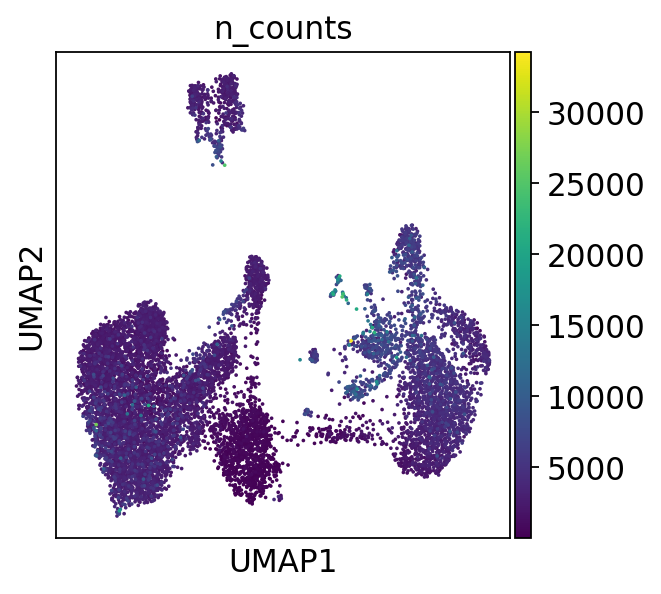

In [13]:
adata_rna.X = adata_rna.layers['X_log1p']
sc.tl.pca(adata_rna, use_highly_variable=True, svd_solver='arpack')
sc.pp.neighbors(adata_rna, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_rna)
sc.pl.umap(adata_rna, color=['n_counts'])

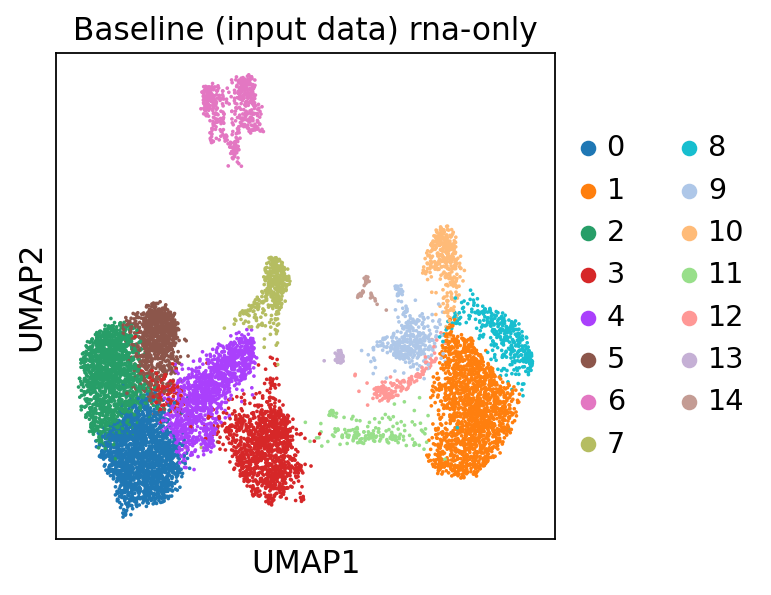

In [52]:
sc.tl.leiden(adata_rna)
sc.pl.umap(adata_rna, color = ['leiden'], title="Baseline (input data) rna-only")

In [15]:
adata_rna.obs['leiden']

AAACAGCCAACAACAA-1    1
AAACAGCCACCGGCTA-1    7
AAACAGCCAGGACACA-1    3
AAACAGCCATCCTAGA-1    1
AAACATGCAAAGGTAC-1    1
                     ..
TTTGTGTTCTAGCGTG-1    2
TTTGTTGGTAAGGTTT-1    1
TTTGTTGGTTAGGATT-1    0
TTTGTTGGTTTGAGCA-1    2
TTTGTTGGTTTGGGCG-1    4
Name: leiden, Length: 10970, dtype: category
Categories (15, object): ['0', '1', '2', '3', ..., '11', '12', '13', '14']

## Combine to create our final dataset

In [16]:
# create new combined adata object
data_combined = np.concatenate(
    [adata_rna.layers["X_binned"], adata_atac.layers["X_binned"]], 
    axis=1
)
data_for_UMAP = np.concatenate(
    [adata_rna.layers["X_log1p"].toarray(), adata_atac.X.toarray() if hasattr(adata_atac.X, "toarray") else adata_atac.X], 
    axis=1
)
combined_var = pd.concat([adata_rna.var, adata_atac.var])

combined_adata = AnnData(
    X=data_combined,
    obs=adata_rna.obs,
    var=pd.DataFrame(index=adata_rna.var_names.tolist() + adata_atac.var_names.tolist()),
    layers={"X_binned": data_combined, "X_UMAP": data_for_UMAP},
)

# add back the gene_name
combined_adata.var['gene_name'] = combined_adata.var.index.tolist()
combined_adata.var["modality"] = ["RNA"] * adata_rna.n_vars + ["ATAC"] * adata_atac.n_vars

In [17]:
# create new gene vocab list to include the peaks
genes = combined_adata.var["gene_name"].tolist()

pretrained_genes = [g for g in genes + special_tokens if g in old_vocab]
new_genes = [g for g in genes + special_tokens if g not in old_vocab]
gene_ids_pretrained = np.array(old_vocab(pretrained_genes), dtype=int)
# https://discuss.pytorch.org/t/expand-an-existing-embedding-and-linear-layer-nan-loss-value/55670/2
# Retrieve pretrained weights
vocab = Vocab(VocabPybind(pretrained_genes + new_genes, None))
vocab.set_default_index(vocab["<pad>"])
gene_ids = np.array(vocab(genes), dtype=int)

In [18]:
# create gene to modality bidirectional dictionary
if config.use_mod:
    gene_rna_df = pd.DataFrame(index = adata_rna.var.index.tolist())
    gene_rna_df['mod'] = 'RNA'
    gene_atac_df = pd.DataFrame(index = adata_atac.var.index.tolist())
    gene_atac_df['mod'] = 'ATAC'
    gene_loc_df = pd.concat([gene_rna_df, gene_atac_df])
    gene_loc_df['mod'] = gene_loc_df['mod'].astype('category')

In [19]:
# create mod vocab
if config.use_mod:
    mod_type = np.array([gene_loc_df.loc[g, 'mod'] for g in genes])
    vocab_mod = Vocab(VocabPybind(np.unique(gene_loc_df['mod']).tolist() + special_tokens, None))
    vocab_mod.set_default_index(vocab_mod["<pad>"])
    mod_type = np.array(vocab_mod(list(mod_type)), dtype=int)
    ntokens_mod = len(vocab_mod)

#### create databank dir

In [20]:
# DataBank.from_anndata(
#     adata=combined_adata,
#     vocab=new_vocab,
#     to="./trial_dataset.scb",
#     main_table_key="X_binned",
#     token_col='gene_name'
# )

In [21]:
# # sanity check for loading
# temp_db = DataBank.from_path('trial_dataset.scb')
# temp_raw_dataset = temp_db.main_data.data
# temp_vocab: GeneVocab = temp_db.gene_vocab


### prepare datasets and loader functions

In [22]:
adata = combined_adata
# del combined_adata
# gc.collect()

In [23]:
adata

AnnData object with n_obs × n_vars = 10970 × 5200
    obs: 'n_counts', 'leiden'
    var: 'gene_name', 'modality'
    layers: 'X_binned', 'X_UMAP'

In [24]:
config.pad_value

-2

In [25]:
# convert to dense representation (np.ndarray)
all_counts = (
    adata.layers[config.input_layer_key].A
    if issparse(adata.layers[config.input_layer_key])
    else adata.layers[config.input_layer_key]
)
genes = adata.var["gene_name"].tolist()

# celltypes_labels = adata.obs["celltype"].tolist()  # make sure count from 0
# num_types = len(set(celltypes_labels))
# celltypes_labels = np.array(celltypes_labels)

# batch_ids = adata.obs["batch_id"].tolist()
# num_batch_types = len(set(batch_ids))
# batch_ids = np.array(batch_ids)

(
    train_data,
    valid_data,
    # train_celltype_labels,
    # valid_celltype_labels,
    # train_batch_labels,
    # valid_batch_labels,
) = train_test_split(
    all_counts, test_size=0.1, shuffle=True
)

In [26]:
num_of_non_zero_genes = [
    np.count_nonzero(train_data[i]) for i in range(train_data.shape[0])
]
print(f"max num of non_zero genes: {np.max(num_of_non_zero_genes)}")
print(f"min num of non_zero genes: {np.min(num_of_non_zero_genes)}")
print(f"average num of non_zero genes: {np.mean(num_of_non_zero_genes)}")
print(
    f"99% quantile num of non_zero genes: {np.quantile(num_of_non_zero_genes, 0.99)}"
)
print(f"max original values: {np.max(train_data)}")
print(
    f"average original non_zero values: {np.mean(train_data[np.nonzero(train_data)])}"
)
print(
    f"99% quantile original non_zero values: {np.quantile(train_data[np.nonzero(train_data)], 0.99)}"
)
# print(f"num of celltypes: {num_types}")

max num of non_zero genes: 2293
min num of non_zero genes: 21
average num of non_zero genes: 430.0684695634559
99% quantile num of non_zero genes: 1371.2800000000007
max original values: 50
average original non_zero values: 25.44946734224103
99% quantile original non_zero values: 49.0


In [27]:
tokenized_train = tokenize_and_pad_batch(
    train_data,
    gene_ids,
    max_len=config.max_seq_len,
    vocab=vocab,
    pad_token=config.pad_token,
    pad_value=config.pad_value,
    append_cls=True,  # append <cls> token at the beginning
    include_zero_gene=config.include_zero_gene,
    mod_type=mod_type if config.use_mod else None,
    vocab_mod=vocab_mod if config.use_mod else None,
)
tokenized_valid = tokenize_and_pad_batch(
    valid_data,
    gene_ids,
    max_len=config.max_seq_len,
    vocab=vocab,
    pad_token=config.pad_token,
    pad_value=config.pad_value,
    append_cls=True,
    include_zero_gene=config.include_zero_gene,
    mod_type=mod_type if config.use_mod else None,
    vocab_mod=vocab_mod if config.use_mod else None,
)
logger.info(
    f"train set number of samples: {tokenized_train['genes'].shape[0]}, "
    f"\n\t feature length: {tokenized_train['genes'].shape[1]}"
)
logger.info(
    f"valid set number of samples: {tokenized_valid['genes'].shape[0]}, "
    f"\n\t feature length: {tokenized_valid['genes'].shape[1]}"
)

scGPT - INFO - train set number of samples: 9873, 
	 feature length: 1201
scGPT - INFO - valid set number of samples: 1097, 
	 feature length: 1201


### Load scGPT_human model weights

In [28]:
model_dict = torch.load(model_file)
ntokens = len(vocab)
num_batch_types = None # temp
model = MultiOmicTransformerModel(
    ntokens,
    embsize,
    nhead,
    d_hid, 
    nlayers,
    vocab=vocab,
    dropout=config.dropout,
    pad_token=config.pad_token,
    pad_value=config.pad_value,
    do_mvc=config.GEPC,
    do_dab=config.DAR,
    use_batch_labels=config.use_batch_labels,
    num_batch_labels=num_batch_types,
    domain_spec_batchnorm=config.DSBN,
    n_input_bins=config.n_bins,
    ecs_threshold=config.ecs_thres,
    explicit_zero_prob=config.explicit_zero_prob,
    use_fast_transformer=config.fast_transformer,
    pre_norm=config.pre_norm,
    use_mod=config.use_mod,
    ntokens_mod=ntokens_mod if config.use_mod else None,
    vocab_mod=vocab_mod if config.use_mod else None,
)

In [29]:
def convert_wqkv(pretrained_dict):
    new_dict = {}
    for k, v in pretrained_dict.items():
        if ".self_attn.Wqkv.weight" in k:
            new_dict[k.replace(".self_attn.Wqkv.weight", ".self_attn.in_proj_weight")] = v
        elif ".self_attn.Wqkv.bias" in k:
            new_dict[k.replace(".self_attn.Wqkv.bias", ".self_attn.in_proj_bias")] = v
        else:
            new_dict[k] = v
    return new_dict

In [30]:
if config.model_path is not None:
    logger.info(f"Detail-oriented graft from: {config.model_path}")
    checkpoint = torch.load(model_file, map_location=config.device)
    model_dict = model.state_dict()

    with torch.no_grad():
        # Use your mapped gene_ids_pretrained to grab the right rows
        pretrained_emb_weights = checkpoint['encoder.embedding.weight'][gene_ids_pretrained, :]
        
        # Graft them into the new, larger embedding table
        # The first len(pretrained_genes) slots get the "knowledge"; the rest (peaks) stay random
        model.encoder.embedding.weight.data[:len(pretrained_genes), :] = pretrained_emb_weights
        
        # Also inherit the normalization weights if they exist in the checkpoint
        if 'encoder.enc_norm.weight' in checkpoint:
            model.encoder.enc_norm.weight.data.copy_(checkpoint['encoder.enc_norm.weight'])
            model.encoder.enc_norm.bias.data.copy_(checkpoint['encoder.enc_norm.bias'])

    # --- 3. THE "BRAIN" TRANSFER (Transformer Blocks) ---
    # We exclude the embedding weight to avoid the shape mismatch crash
    # Everything else (Attention, MLP, LayerNorms) flows in
    filtered_checkpoint = {
        k.replace("module.", ""): v 
        for k, v in checkpoint.items() 
        if k.replace("module.", "") != 'encoder.embedding.weight' 
        and not k.replace("module.", "").startswith('decoder.')      # Exclude decoder
        and not k.replace("module.", "").startswith('mvc_decoder.')
    }

    if config.fast_transformer == False:
        print("renaming pretrained model keys to account for fast_transformer = False")
        pretrained_dict_renamed = convert_wqkv(filtered_checkpoint)
        filtered_checkpoint.update(pretrained_dict_renamed)

    # strict=False allows the model to skip the decoder weights we just filtered out
    missing_keys, unexpected_keys = model.load_state_dict(filtered_checkpoint, strict=False)
    
    logger.info(f"Graft complete. Transformer knowledge inherited. Decoder will train from scratch.")
    
    # Track what is actually missing to ensure it's what we expect
    new_layers = [k for k in missing_keys if any(x in k for x in ['mod_encoder', 'bn', 'decoder', 'mvc'])]
    logger.info(f"New/Reset layers: {new_layers}")

model.to(config.device)

scGPT - INFO - Detail-oriented graft from: ../scGPT_human
renaming pretrained model keys to account for fast_transformer = False
scGPT - INFO - Graft complete. Transformer knowledge inherited. Decoder will train from scratch.
scGPT - INFO - New/Reset layers: ['mod_encoder.embedding.weight', 'mod_encoder.enc_norm.weight', 'mod_encoder.enc_norm.bias', 'decoder.fc.0.weight', 'decoder.fc.0.bias', 'decoder.fc.2.weight', 'decoder.fc.2.bias', 'decoder.fc.4.weight', 'decoder.fc.4.bias', 'cls_decoder._decoder.0.weight', 'cls_decoder._decoder.0.bias', 'cls_decoder._decoder.2.weight', 'cls_decoder._decoder.2.bias', 'cls_decoder._decoder.3.weight', 'cls_decoder._decoder.3.bias', 'cls_decoder._decoder.5.weight', 'cls_decoder._decoder.5.bias', 'cls_decoder.out_layer.weight', 'cls_decoder.out_layer.bias', 'mvc_decoder.gene2query.weight', 'mvc_decoder.gene2query.bias', 'mvc_decoder.W.weight']


MultiOmicTransformerModel(
  (encoder): GeneEncoder(
    (embedding): Embedding(5203, 512, padding_idx=1029)
    (enc_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (value_encoder): ContinuousValueEncoder(
    (dropout): Dropout(p=0.2, inplace=False)
    (linear1): Linear(in_features=1, out_features=512, bias=True)
    (activation): ReLU()
    (linear2): Linear(in_features=512, out_features=512, bias=True)
    (norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (mod_encoder): BatchLabelEncoder(
    (embedding): Embedding(5, 512, padding_idx=2)
    (enc_norm): LayerNorm((512,), eps=1e-05, elementwise_affine=True)
  )
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-3): 4 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
        )
        (linear1): Linear(in_features=512, out_features=512, bias=True)
    

In [31]:
missing_keys

['encoder.embedding.weight',
 'mod_encoder.embedding.weight',
 'mod_encoder.enc_norm.weight',
 'mod_encoder.enc_norm.bias',
 'decoder.fc.0.weight',
 'decoder.fc.0.bias',
 'decoder.fc.2.weight',
 'decoder.fc.2.bias',
 'decoder.fc.4.weight',
 'decoder.fc.4.bias',
 'cls_decoder._decoder.0.weight',
 'cls_decoder._decoder.0.bias',
 'cls_decoder._decoder.2.weight',
 'cls_decoder._decoder.2.bias',
 'cls_decoder._decoder.3.weight',
 'cls_decoder._decoder.3.bias',
 'cls_decoder._decoder.5.weight',
 'cls_decoder._decoder.5.bias',
 'cls_decoder.out_layer.weight',
 'cls_decoder.out_layer.bias',
 'mvc_decoder.gene2query.weight',
 'mvc_decoder.gene2query.bias',
 'mvc_decoder.W.weight']

## Train it

In [32]:
# # specify training modules

# criterion_gep_gepc = masked_mse_loss
# optimizer = torch.optim.Adam(
#     model.parameters(), lr=config.lr, eps=1e-4 if config.amp else 1e-8
# )
# scheduler = torch.optim.lr_scheduler.StepLR(optimizer, 1, gamma=config.schedule_ratio)
# scaler = torch.cuda.amp.GradScaler(enabled=config.amp)

In [43]:
tokenized_train

{'genes': tensor([[1030,   35,   46,  ..., 1029, 1029, 1029],
         [1030,    1,    5,  ..., 1029, 1029, 1029],
         [1030,   33,   35,  ..., 1029, 1029, 1029],
         ...,
         [1030,   28,   48,  ..., 1029, 1029, 1029],
         [1030,   42,   46,  ..., 1029, 1029, 1029],
         [1030,   45,   46,  ..., 1029, 1029, 1029]]),
 'values': tensor([[ 0.,  2., 30.,  ..., -2., -2., -2.],
         [ 0., 12., 17.,  ..., -2., -2., -2.],
         [ 0., 11., 18.,  ..., -2., -2., -2.],
         ...,
         [ 0., 18., 31.,  ..., -2., -2., -2.],
         [ 0., 45., 50.,  ..., -2., -2., -2.],
         [ 0.,  4., 46.,  ..., -2., -2., -2.]]),
 'mod_types': tensor([[3, 1, 1,  ..., 2, 2, 2],
         [3, 1, 1,  ..., 2, 2, 2],
         [3, 1, 1,  ..., 2, 2, 2],
         ...,
         [3, 1, 1,  ..., 2, 2, 2],
         [3, 1, 1,  ..., 2, 2, 2],
         [3, 1, 1,  ..., 2, 2, 2]])}

## Extract zero-shot embedding (change to post-training later)

Although decoder is randomly initialized, it's actually fine since we are not using them anyways, we extract the embedding at last attention layer

### First get the initial representation

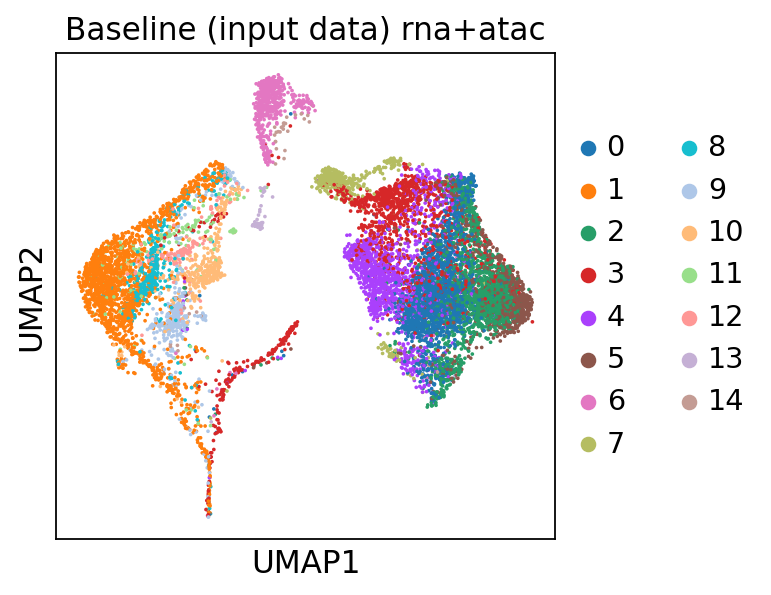

In [53]:
# Create the temporary visualization object
baseline_adata = combined_adata.copy()
baseline_adata.X = combined_adata.layers["X_UMAP"]

# 1. Explicitly run PCA first to reduce 5200 dims -> 40 dims
# This removes the "noise" while keeping the biological signal
sc.pp.pca(baseline_adata, n_comps=40)

# 2. Now run neighbors on the PCA representation (no more warning!)
sc.pp.neighbors(baseline_adata, n_neighbors=15, n_pcs=40)

# 3. Compute and plot
sc.tl.umap(baseline_adata)
sc.pl.umap(baseline_adata, color='leiden', title="Baseline (input data) rna+atac")

In [48]:
# no training just let it go through once (inference) and extract last layer before decoder then plot umap, takes the loader as input
def get_scgpt_embeddings(model, loader, vocab, config, device):
    """
    Extracts latent embeddings from scGPT without updating weights.
    """
    model.eval()
    model.to(device)

    cell_embeddings = []
    with torch.no_grad():
        for batch_data in tqdm(loader, desc="Extracting embeddings"):
            # Mirroring your evaluate() tensor loading exactly
            input_gene_ids = batch_data["gene_ids"].to(device)
            input_values = batch_data["values"].to(device)
            batch_labels = batch_data["batch_labels"].to(device)
            
            if config.task == "multiomic":
                mod_types = batch_data["mod_types"].to(device)
            else:
                mod_types = None

            src_key_padding_mask = input_gene_ids.eq(vocab[config.pad_token])

            with torch.cuda.amp.autocast(enabled=config.amp):
                output_dict = model(
                    input_gene_ids,
                    input_values,
                    src_key_padding_mask=src_key_padding_mask,
                    batch_labels=batch_labels if (config.use_batch_labels or config.DSBN) else None,
                    CLS=False,   # Forced True to get the cell vector for the UMAP
                    MVC=False,  # Matches your evaluate()
                    ECS=False,  # Matches your evaluate()
                    mod_types=mod_types if config.use_mod else None,
                )
            
            # Grab the latent vector. In scGPT, this is 'cell_emb'. 
            embedding_key = "cell_emb" if "cell_emb" in output_dict else "cls_output"
            curr_emb = output_dict[embedding_key].detach().cpu()
            
            cell_embeddings.append(curr_emb)

    # 4. Finalize and save
    combined_embeddings = np.concatenate(cell_embeddings, axis=0)
    
    return combined_embeddings

random masking at epoch   1, ratio of masked values in train:  0.3991


Extracting embeddings: 100%|██████████| 686/686 [00:20<00:00, 33.06it/s]


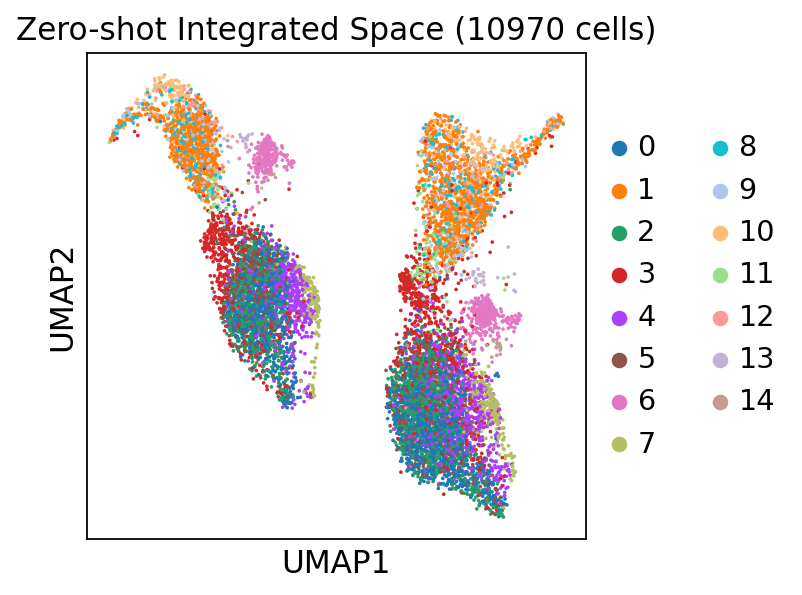

In [50]:
# using the all_counts, we construct a general interpretation of a zero_shot embedding 

tokenized_all = tokenize_and_pad_batch(
    all_counts,
    gene_ids,
    max_len=config.max_seq_len,
    vocab=vocab,
    pad_token=config.pad_token,
    pad_value=config.pad_value,
    append_cls=True,
    include_zero_gene=config.include_zero_gene,
    mod_type=mod_type if config.use_mod else None,
    vocab_mod=vocab_mod if config.use_mod else None,
)

full_dataset, _ = prepare_data(
    tokenized_train=tokenized_all, 
    tokenized_valid=tokenized_all, 
    train_batch_labels=np.ones_like(tokenized_all['values']),
    valid_batch_labels=np.ones_like(tokenized_all['values']),
    config=config,
    epoch=1, # Dummy epoch
    sort_seq_batch=False
)

full_loader = prepare_dataloader(
    full_dataset, 
    batch_size=config.batch_size, 
    shuffle=False, # Keep original order
    drop_last=False
)

zero_shot_embeddings = get_scgpt_embeddings(model, full_loader, vocab, config, device=config.device)
zero_shot_adata = sc.AnnData(X=zero_shot_embeddings, obs=combined_adata.obs.copy())
zero_shot_adata.obsm["X_scGPT"] = zero_shot_embeddings

# No PCA for transformer latents
sc.pp.neighbors(zero_shot_adata, use_rep="X_scGPT", n_neighbors=15)
sc.tl.umap(zero_shot_adata)
sc.pl.umap(zero_shot_adata, color='leiden', title=f"Zero-shot Integrated Space ({zero_shot_adata.n_obs} cells)")